## Prompts in langgraph
"A prompt is an instruction or input provided to an LLM to guide its behaviour and generate the desired response."

In [5]:
#Step 1 : Intializing the model
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

response = llm.invoke("Give me a funfact about India")
print(response.content)

Did you know? India is home to the world’s only **floating post office**! Located on Dal Lake in Srinagar, the “Bharat Post” service operates from a boat that delivers mail, parcels, and even offers a small souvenir shop—all while gently bobbing on the water. It’s a unique blend of tradition and ingenuity that’s become a popular tourist attraction and a quirky piece of India’s postal history. 🌊📬


In [6]:
# A. PromptTemplate
# Normal text-based prompt create karne ke liye.

from langchain_core.prompts import PromptTemplate

prompt = PromptTemplate.from_template(
    "Explain {topic} in simple words."
)

result = prompt.invoke({
    "topic": "LangGraph"
})

print(result)


text='Explain LangGraph in simple words.'


In [7]:
# B. ChatPromptTemplate
# Chat models ke liye structured messages create karta hai.

from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful AI tutor."),
    ("human", "Explain {topic} in simple words.")
])

## Chain With Prompts

"A chain is a sequence of connected components where the output of one component becomes the input of the next component."

chain = prompt | llm

## LangGraph mein hum LangChain ke prompts aur chains ko nodes ke andar use kar sakte hain. 
Matlab:
- LangChain prompt create karega.
- LangChain chain execute karegi.
- LangGraph workflow ko control karega.

In [8]:
#Define state

from langgraph.graph import StateGraph
from typing import TypedDict

class GraphState(TypedDict):
    topic: str
    response: str


#create Prompt 
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful AI tutor."),
    ("human", "Explain {topic} in simple words.")
])


#create Chain :
from langchain_core.output_parsers import StrOutputParser

chain = prompt | llm | StrOutputParser()


#create Node :
def chatbot(state: GraphState):

    response = chain.invoke({
        "topic": state["topic"]
    })

    return {
        "response": response
    }

    #Notice something important:

# chain.invoke() ko hum node ke andar call kar rahe hain.



# Creategraph 

from langgraph.graph import START, END

builder = StateGraph(GraphState)

builder.add_node("chatbot", chatbot)

builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

graph = builder.compile()

In [9]:
# Invoke 

result = graph.invoke({
    "topic": "LangGraph",
    "response": ""
})

print(result["response"])

**LangGraph – a simple way to picture “thinking steps” for language‑model programs**

Imagine you’re building a robot that can have a conversation, look up facts, do a calculation, or even draw a picture. To make the robot work, you need to tell it **what to do first, what to do next, and what to do if something goes wrong**.  

LangGraph is a library (for Python) that helps you draw that “to‑do list” as a **graph**—a set of nodes (steps) connected by arrows (the flow of control). Each node can be:

* **A language‑model call** (e.g., “Ask GPT‑4 to summarize this text”)
* **A tool call** (e.g., “Search the web”, “Run a calculator”, “Call an API”)
* **A piece of custom Python code** (e.g., “store the result in a database”)

The arrows tell the system **how to move from one node to the next**. Because it’s a graph, you can have:

* **Linear chains** – A → B → C (simple step‑by‑step)
* **Branches** – A → B *or* A → C (choose a path based on a condition)
* **Loops** – A → B → A (repeat unti

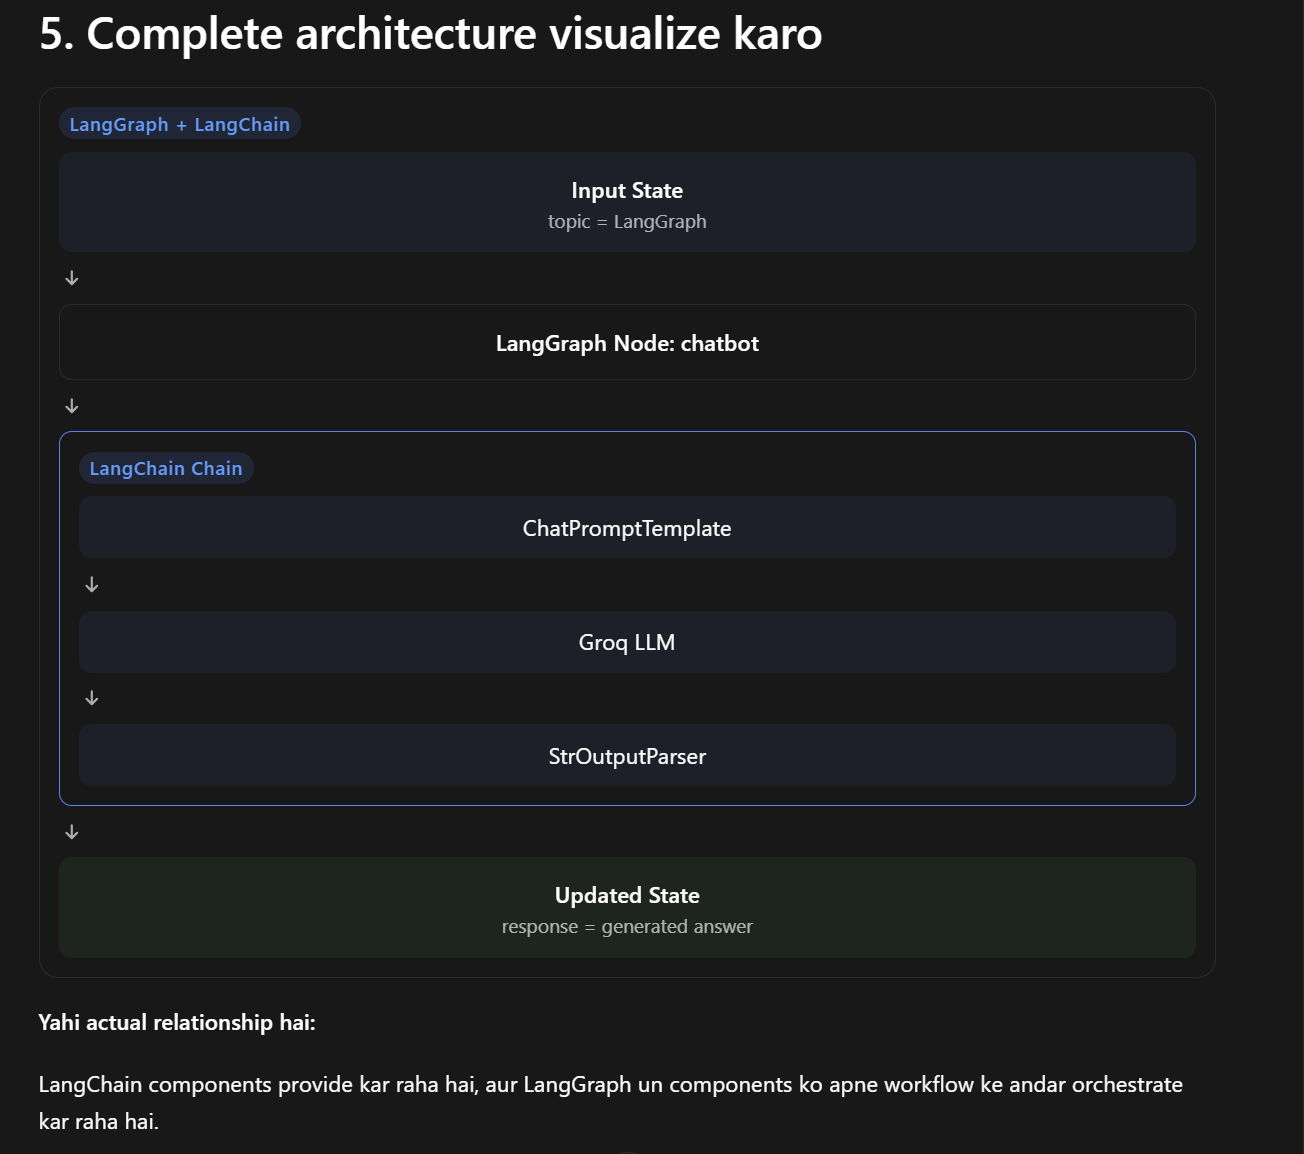